# Multiple axes and per-sample limits

A problem with `Naxis` axes solves all of them together. The waveform `X` is flat and axis-major:
`X.reshape(Naxis, N)` gives one row per axis. Constraints that act on one axis take an `axis` argument
(moments), while the hardware limits apply to every axis.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import gropt

## Per-axis or rotation-invariant limits

With `rot_variant=True` (the default) `add_gmax` and `add_smax` limit each axis on its own. With
`rot_variant=False` they limit the magnitude over the axes, ‖g(t)‖ ≤ gmax, which holds whatever the
orientation of the scan. Here: flow encoding along x and y together (an oblique direction).

rot_variant=True : N = 133, max |g| = 88.1 mT/m, max |slew| = 282 T/m/s
rot_variant=False: N = 149, max |g| = 71.0 mT/m, max |slew| = 200 T/m/s


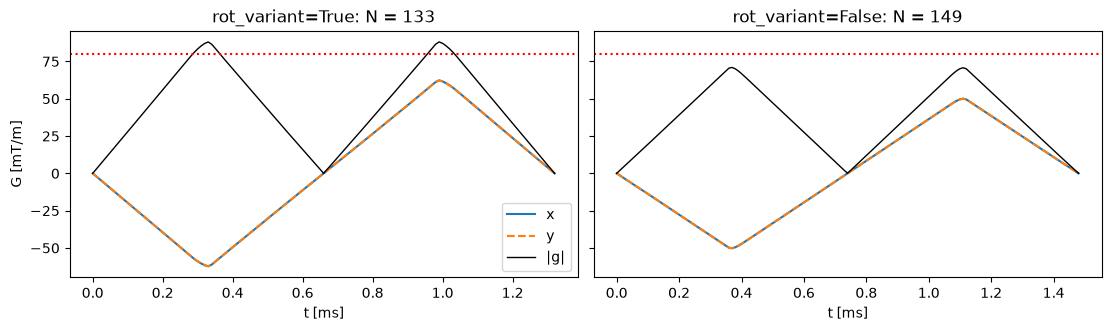

In [2]:
def oblique_flow(N, rot_variant):
    gp = gropt.GroptParams()
    gp.dt = 10e-6
    gp.N = N
    gp.Naxis = 2
    gp.vec_init_simple()
    gp.add_gmax(0.08, rot_variant=rot_variant)
    gp.add_smax(200, rot_variant=rot_variant)
    for axis in (0, 1):
        gp.add_moment(0, 0.0, axis=axis, project=True)
        gp.add_moment(1, 14.0, axis=axis, project=True)
    return gp


def shortest(make, lo, hi):
    """Smallest N in (lo, hi] whose solve converges (see the flow-encoding example)."""
    best = gropt.solve(make(hi))
    if not best.converged:
        raise ValueError(f'N = {hi} is not feasible; raise hi')
    while hi - lo > 1:
        mid = (lo + hi) // 2
        r = gropt.solve(make(mid))
        if r.converged:
            hi, best = mid, r
        else:
            lo = mid
    return hi, best


fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout='constrained', sharey=True)
for ax, rot_variant in zip(axs, (True, False)):
    N, r = shortest(lambda N: oblique_flow(N, rot_variant), 50, 400)
    G = r.X.reshape(2, N)
    t_ms = np.arange(N) * 10e-3
    ax.plot(t_ms, G[0] * 1e3, label='x')
    ax.plot(t_ms, G[1] * 1e3, '--', label='y')
    ax.plot(t_ms, np.linalg.norm(G, axis=0) * 1e3, 'k', lw=1, label='|g|')
    ax.axhline(80, ls=':', color='r')
    ax.set(title=f'rot_variant={rot_variant}: N = {N}', xlabel='t [ms]')
    print(f'rot_variant={rot_variant!s:5}: N = {N}, max |g| = {1e3 * np.linalg.norm(G, axis=0).max():.1f} mT/m, '
          f'max |slew| = {np.linalg.norm(np.diff(G), axis=0).max() / 10e-6:.0f} T/m/s')
axs[0].set_ylabel('G [mT/m]')
axs[0].legend()
plt.show()

The per-axis limits let both axes use the full 200 T/m/s at once (283 T/m/s combined), which is only
allowed if the waveform is played in this orientation. With the rotation-invariant limits each axis gets
200/√2 T/m/s here, and since the duration of a slew-limited flow encode scales as
smax^(-1/3), the waveform is 2^(1/6) ≈ 1.12 times longer.

## Limits that change over time

`add_gmax_vec` and `add_smax_vec` take one limit per sample (N for the gradient, N − 1 for the slew; a
length of `Naxis` times that sets each axis separately). Here the slew is limited to 50 T/m/s during the
middle third of a single-axis flow encode, for example to avoid an acoustic resonance or another
event.

SolveResult(converged=True, n_iter=26, n_feval=115, X.size=200)


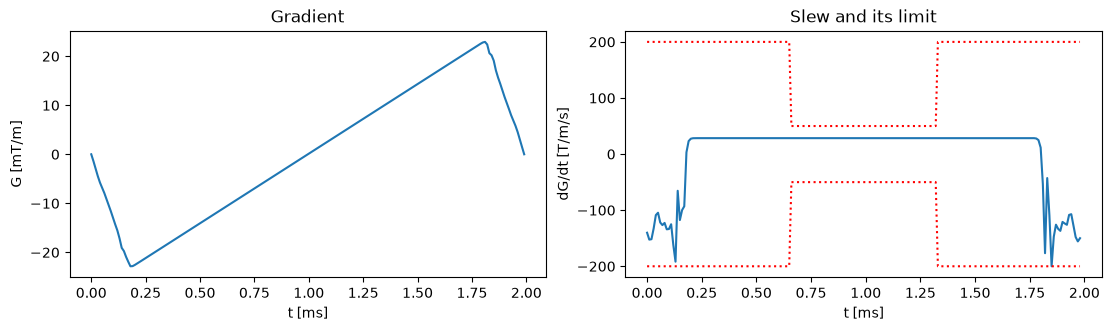

In [3]:
N = 200
smax_vec = np.full(N - 1, 200.0)
smax_vec[N // 3: 2 * N // 3] = 50.0

gp = gropt.GroptParams()
gp.dt = 10e-6
gp.N = N
gp.vec_init_simple()
gp.add_gmax(0.08)
gp.add_smax_vec(smax_vec)
gp.add_moment(0, 0.0, project=True)
gp.add_moment(1, 14.0, project=True)
r = gropt.solve(gp)
print(r)

t_ms = np.arange(N) * 10e-3
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout='constrained')
axs[0].plot(t_ms, r.X * 1e3)
axs[0].set(xlabel='t [ms]', ylabel='G [mT/m]', title='Gradient')
axs[1].plot(t_ms[:-1], np.diff(r.X) / 10e-6)
axs[1].plot(t_ms[:-1], smax_vec, ':r')
axs[1].plot(t_ms[:-1], -smax_vec, ':r')
axs[1].set(xlabel='t [ms]', ylabel='dG/dt [T/m/s]', title='Slew and its limit')
plt.show()